# Euler法からRunge–Kutta法を導出する

## 概要

Euler法から2次法、古典的4次Runge–Kutta法をTaylor展開の係数比較で導く。Pythonで解、誤差、計算量、安定性を比較する。

## 実行環境

環境・カーネルは **wa-src(3.14.6)**、Pythonは **3.14.6** である。ノートブックのフォルダーでセルを上から実行する。図は `105_nb_files` にSVGで保存する。小数の表示は有効数字3桁とし、内部計算は丸めない。

In [1]:
import platform
from pathlib import Path
from pprint import pprint

import numpy as np
import sympy as sp
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats

%matplotlib inline
set_matplotlib_formats("svg")

print("Python:", platform.python_version())
for package in (np, sp, matplotlib):
    print(f"{package.__name__}: {package.__version__}")

# 図の保存先を準備する。
out = Path("105_nb_files")
out.mkdir(exist_ok=True)

def sig(value):
    return f"{value:#.3g}"

plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

def formula(tex):
    # LaTeXとHTMLの区切りを使い分ける。
    display({"text/latex": r"\(" + tex + r"\)",
             "text/html": "<div>$$" + tex + "$$</div>"}, raw=True)

def save(fig, name):
    for ax in fig.axes:
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: sig(x)))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: sig(x)))
        ax.minorticks_off()
        ax.grid(alpha=0.300)
        ax.legend()
    fig.tight_layout()
    fig.savefig(out / f"{name}.svg", format="svg")
    plt.show()
    plt.close(fig)

Python: 3.14.6
numpy: 2.5.4
sympy: 1.14.0
matplotlib: 3.11.2


## 1. Euler法は積分を長方形で近似する

初期値問題 $y'=f(t,y),\ y(t_0)=y_0$ を考える。刻み幅を $h>0$、$t_n=t_0+nh$、近似値を $y_n\approx y(t_n)$ とする。$f$ は十分滑らかで、$y$ について局所Lipschitz連続とする。

1区間で積分すると、

$$
y(t_n+h)-y(t_n)=\int_{t_n}^{t_n+h}f(t,y(t))\,dt.
$$

傾きを左端の値で置き換えると積分は $hf(t_n,y_n)$ となり、陽的Euler法を得る。

In [2]:
formula(r"\boxed{y_{n+1}=y_n+hf(t_n,y_n)}")

$$\boxed{y_{n+1}=y_n+hf(t_n,y_n)}$$

以下、$f$ とその偏導関数は始点で評価する。

$$
\begin{aligned}
y''&=\frac{d}{dt}f(t,y(t))=f_t+f_y y'=f_t+f_yf,\\
y(t+h)&=y(t)+hf+\frac{h^2}{2}(f_t+f_yf)+O(h^3).
\end{aligned}
$$

Euler法は $h^2$ の項を落とす。真の値から1ステップ進めた誤差を局所誤差と呼ぶと、これは $O(h^2)$ である。固定区間での誤差は後述の条件下で $O(h)$ になる。

## 2. 傾きをもう1回評価する

2段の公式を考える。$k_i$ は $h$ を含まない傾きである。

$$
k_1=f(t_n,y_n),\quad k_2=f(t_n+ch,y_n+ahk_1),\quad
y_{n+1}=y_n+h(b_1k_1+b_2k_2).
$$

Taylor展開すると、

$$
\begin{aligned}
k_2&=f+chf_t+ahff_y+O(h^2),\\
y_{n+1}&=y_n+h(b_1+b_2)f+h^2(b_2cf_t+b_2aff_y)+O(h^3).
\end{aligned}
$$

$f,f_t,ff_y$ の係数比較から、

$$
b_1+b_2=1,\quad b_2c=\frac12,\quad b_2a=\frac12.
$$

したがって $c=a\ne0$、$b_2=1/(2a)$、$b_1=1-1/(2a)$ である。$a=1/2$ を選ぶと陽的中点法、$a=1$ を選ぶとHeun法になる。

$$
\begin{aligned}
\text{中点法: }&y_{n+1}=y_n+h f\left(t_n+\frac h2,y_n+\frac h2 f(t_n,y_n)\right),\\
\text{Heun法: }&y_{n+1}=y_n+\frac h2\{f(t_n,y_n)+f(t_n+h,y_n+hf(t_n,y_n))\}.
\end{aligned}
$$

局所誤差はどちらも $O(h^3)$ である。図1は $y'=-y,\ y(0)=1,\ h=0.800$ の例である。中点はEuler法による予測位置である。私は、この点を図で確認すると式を追いやすいと感じる。

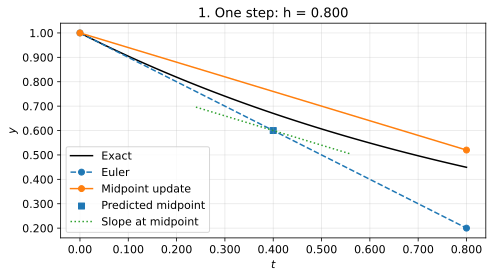

In [3]:
h = 0.800
t = np.linspace(0, h, 100)
mid_y = 1 - h / 2
fig, ax = plt.subplots()
ax.plot(t, np.exp(-t), "k", label="Exact")
ax.plot([0, h], [1, 1 - h], "o--", label="Euler")
ax.plot([0, h], [1, 1 - h * mid_y], "o-", label="Midpoint update")
ax.scatter([h / 2], [mid_y], marker="s", label="Predicted midpoint")
dt = np.array([-1, 1]) * h / 5
ax.plot(h / 2 + dt, mid_y - mid_y * dt,
        ":", color="tab:green", label="Slope at midpoint")
ax.set(xlabel="$t$", ylabel="$y$", title="1. One step: h = 0.800")
save(fig, "01_one_step")

## 3. 4次Runge–Kutta法の係数を求める

### 4段の傾きを展開する

始点、中点、中点、終点で傾きを評価する形を選ぶ。重みを決め、4次の項まで一致するか確認する。

$$
\begin{aligned}
k_1&=f(t,y),&k_2&=f(t+h/2,y+hk_1/2),\\
k_3&=f(t+h/2,y+hk_2/2),&k_4&=f(t+h,y+hk_3),\\
y_{n+1}&=y+h\sum_{i=1}^4b_i k_i.&&
\end{aligned}
$$

$t=t_n,y=y_n$ と略記し、次を定義する。

$$
\begin{aligned}
q&=f_y,& A&=f_t+qf,&D&=f_{ty}+f_{yy}f,\\
B&=f_{tt}+2f_{ty}f+f_{yy}f^2,\\
C&=f_{ttt}+3f_{tty}f+3f_{tyy}f^2+f_{yyy}f^3.
\end{aligned}
$$

連鎖律から、真の解に沿った微分を求める。

$$
\begin{aligned}
\frac{dq}{dt}&=D,\\
\frac{dA}{dt}&=f_{tt}+f_{ty}f+(f_{yt}+f_{yy}f)f+qA=B+qA,\\
\frac{dB}{dt}&=f_{ttt}+f_{tty}f+2(f_{tty}+f_{tyy}f)f
 +2f_{ty}A+(f_{tyy}+f_{yyy}f)f^2+2f_{yy}fA\\
&=C+2DA,\\
y^{(4)}&=\frac{d}{dt}(B+qA)=C+2DA+DA+q(B+qA)\\
&=C+3DA+qB+q^2A.
\end{aligned}
$$

よって真の解の展開は、

$$
y(t+h)=y+hf+\frac{h^2}{2}A+\frac{h^3}{6}(B+qA)
+\frac{h^4}{24}(C+3DA+qB+q^2A)+O(h^5).
$$

各段には次の2変数Taylor展開を使う。

$$
\begin{aligned}
f(t+u,y+v)={}&f+uf_t+vf_y
+\frac12(u^2f_{tt}+2uvf_{ty}+v^2f_{yy})\\
&+\frac16(u^3f_{ttt}+3u^2vf_{tty}+3uv^2f_{tyy}+v^3f_{yyy})+O(h^4),
\end{aligned}
$$

$u,v=O(h)$ とする。$k_2$ には $(u,v)=(h/2,hf/2)$、$k_3,k_4$ には、

$$
\begin{aligned}
\frac h2 k_2&=\frac h2f+\frac{h^2}{4}A+\frac{h^3}{16}B+O(h^4),\\
hk_3&=hf+\frac{h^2}{2}A+h^3\left(\frac B8+\frac{qA}4\right)+O(h^4)
\end{aligned}
$$

を順に $v$ へ代入し、整理する。

$$
\begin{aligned}
k_1={}&f,\\
k_2={}&f+\frac h2A+\frac{h^2}{8}B+\frac{h^3}{48}C+O(h^4),\\
k_3={}&f+\frac h2A+h^2\left(\frac B8+\frac{qA}4\right)
+h^3\left(\frac C{48}+\frac{DA}8+\frac{qB}{16}\right)+O(h^4),\\
k_4={}&f+hA+h^2\left(\frac B2+\frac{qA}2\right)
+h^3\left(\frac C6+\frac{DA}2+\frac{qB}8+\frac{q^2A}4\right)+O(h^4).
\end{aligned}
$$

### 重みを決める

$y+h\sum b_i k_i$ と真の解を比較する。$hf,h^2A,h^3B,h^3qA$ の係数から、

$$
\sum b_i=1,\quad \frac{b_2+b_3}{2}+b_4=\frac12,\quad
\frac{b_2+b_3}{8}+\frac{b_4}{2}=\frac16,\quad
\frac{b_3}{4}+\frac{b_4}{2}=\frac16.
$$

第3式を4倍して第2式を引くと、$b_4=2/3-1/2=1/6$ となる。第2式から $b_2+b_3=2/3$、第4式から $b_3=4(1/6-1/12)=1/3$、したがって $b_2=1/3$、$b_1=1/6$ である。

残る $h^4$ の4項も確認する。

$$
\begin{aligned}
C:&\quad\frac{b_2+b_3}{48}+\frac{b_4}{6}=\frac1{72}+\frac1{36}=\frac1{24},\\
DA:&\quad\frac{b_3}{8}+\frac{b_4}{2}=\frac1{24}+\frac1{12}=\frac18,\\
qB:&\quad\frac{b_3}{16}+\frac{b_4}{8}=\frac1{48}+\frac1{48}=\frac1{24},\\
q^2A:&\quad\frac{b_4}{4}=\frac1{24}.
\end{aligned}
$$

すべて一致し、局所誤差は $O(h^5)$ となる。これが古典的4次Runge–Kutta法（RK4）である。4次法は一意ではない。

In [4]:
formula(r"\boxed{y_{n+1}=y_n+\frac h6(k_1+2k_2+2k_3+k_4)}")

$$\boxed{y_{n+1}=y_n+\frac h6(k_1+2k_2+2k_3+k_4)}$$

### 局所誤差から全体の誤差へ

局所誤差が $Kh^{p+1}$ 以下で、1ステップ写像がLipschitz定数 $1+Lh$ を持つとする。初期誤差は0、$L>0$、$Nh=T$ とすると、

$$
\begin{aligned}
|e_{n+1}|&\le(1+Lh)|e_n|+Kh^{p+1},\\
|e_N|&\le Kh^{p+1}\sum_{j=0}^{N-1}(1+Lh)^j
=\frac K L h^p\{(1+Lh)^N-1\}\\
&\le\frac K L(e^{LT}-1)h^p=O(h^p).
\end{aligned}
$$

Euler法は1次、中点法とHeun法は2次、RK4は4次となる。解が存在する固定区間で、十分小さい刻み幅に対する評価である。

## 4. Pythonで解と誤差を比較する

1ステップと反復計算を実装する。$n$ はステップ数である。

In [5]:
def step(f, t, y, h, name):
    k1 = f(t, y)
    if name == "Euler":
        return y + h * k1
    if name == "Heun":
        k2 = f(t + h, y + h * k1)
        return y + h * (k1 + k2) / 2
    k2 = f(t + h / 2, y + h * k1 / 2)
    if name == "Midpoint":
        return y + h * k2
    if name != "RK4":
        raise ValueError(name)
    k3 = f(t + h / 2, y + h * k2 / 2)
    k4 = f(t + h, y + h * k3)
    return y + h * (k1 + 2 * k2 + 2 * k3 + k4) / 6


def solve(f, end, y0, n, name):
    h = end / n
    t = np.linspace(0, end, n + 1)
    y = np.empty(n + 1)
    y[0] = y0
    for i in range(n):
        y[i + 1] = step(f, t[i], y[i], h, name)
    return t, y


# 段数は関数評価回数である。
stages = {"Euler": 1, "Midpoint": 2, "Heun": 2, "RK4": 4}

非線形な例 $y'=(1+2t)y(1-y),\ y(0)=1/4$ を変数分離する。

$$
\frac{dy}{y(1-y)}=(1+2t)dt,\quad
\log\frac{y}{1-y}=t+t^2-\log3,\quad
y(t)=\frac1{1+3e^{-t-t^2}}.
$$

図2は解、図3は絶対誤差である。誤差0の初期点は対数軸から除く。

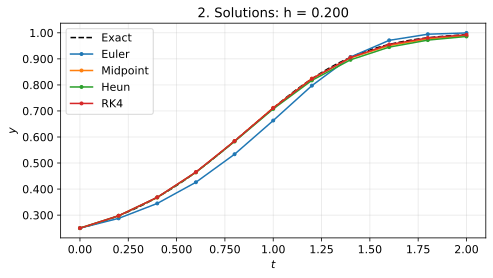

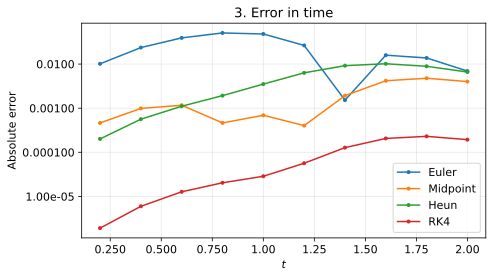

{'Euler': '0.0507', 'Heun': '0.0102', 'Midpoint': '0.00477', 'RK4': '0.000230'}


In [6]:
def rhs(t, y):
    return (1 + 2 * t) * y * (1 - y)


def exact(t):
    return 1 / (1 + 3 * np.exp(-t - t**2))


solutions = {m: solve(rhs, 2, 1 / 4, 10, m) for m in stages}
fig, ax = plt.subplots()
dense = np.linspace(0, 2, 400)
ax.plot(dense, exact(dense), "k--", label="Exact")
for name, (t, y) in solutions.items():
    ax.plot(t, y, ".-", label=name)
ax.set(xlabel="$t$", ylabel="$y$", title="2. Solutions: h = 0.200")
save(fig, "02_solutions")

fig, ax = plt.subplots()
for name, (t, y) in solutions.items():
    error = np.abs(y - exact(t))
    ax.semilogy(t[1:], error[1:], ".-", label=name)
ax.set(xlabel="$t$", ylabel="Absolute error", title="3. Error in time")
save(fig, "03_errors")
pprint({m: sig(np.max(np.abs(y - exact(t))))
        for m, (t, y) in solutions.items()})

### 刻み幅と関数評価回数

区間 $[0,1]$ で $E(h)=\max_n|y_n-y(t_n)|$ を求める。$E(h)\approx Ch^p$ なら、

$$
\frac{E(h)}{E(h/2)}\approx2^p,\qquad
p_{\mathrm{obs}}=\frac{\log(E(h)/E(h/2))}{\log2}.
$$

図4で次数、図5で関数評価回数と誤差を確認する。同じ刻み幅ならRK4はEuler法の4倍の関数評価を使う。

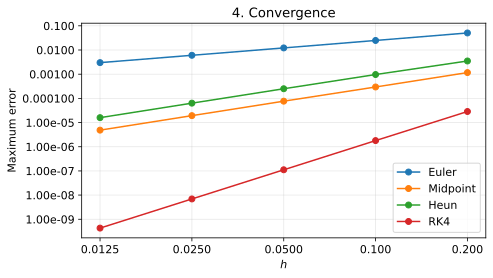

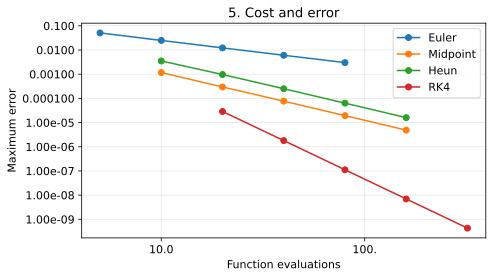

{'Euler': '1.01', 'Heun': '1.99', 'Midpoint': '1.99', 'RK4': '4.00'}


In [7]:
counts = np.array([5, 10, 20, 40, 80])
hs = 1 / counts
errors = {}
for name in stages:
    values = []
    for n in counts:
        t, y = solve(rhs, 1, 1 / 4, int(n), name)
        values.append(np.max(np.abs(y - exact(t))))
    errors[name] = np.array(values)

for cost in (False, True):
    fig, ax = plt.subplots()
    for name, error in errors.items():
        x = counts * stages[name] if cost else hs
        ax.loglog(x, error, "o-", label=name)
    ax.set(xlabel="Function evaluations" if cost else "$h$",
           ylabel="Maximum error",
           title="5. Cost and error" if cost else "4. Convergence")
    if not cost:
        ax.set_xticks(hs)
    save(fig, "05_cost" if cost else "04_convergence")

# 最後の2点の観測次数。
pprint({m: sig(np.log2(e[-2] / e[-1])) for m, e in errors.items()})

## 5. 高次でも刻み幅に制約がある

$y'=\lambda y$ に適用し、$z=h\lambda$ と置くと $y_{n+1}=R(z)y_n$ となる。Euler法は $R(z)=1+z$、中点法は $1+z(1+z/2)=1+z+z^2/2$ である。$y_n=1,h=1,\lambda=z$ として各法の増幅率を記号計算する。

$$R_{\mathrm{Euler}}(z)=z + 1$$

$$R_{\mathrm{Midpoint}}(z)=\frac{z^{2}}{2} + z + 1$$

$$R_{\mathrm{Heun}}(z)=\frac{z^{2}}{2} + z + 1$$

$$R_{\mathrm{RK4}}(z)=\frac{z^{4}}{24} + \frac{z^{3}}{6} + \frac{z^{2}}{2} + z + 1$$

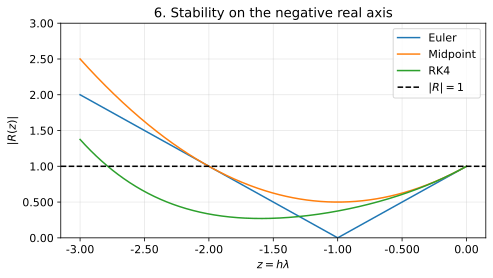

In [8]:
z = sp.symbols("z")
poly = {}
for name in stages:
    r = sp.expand(step(lambda t, y: z * y, 0, sp.Integer(1), 1, name))
    poly[name] = r
    formula(r"R_{\mathrm{" + name + r"}}(z)=" + sp.latex(r))

grid = np.linspace(-3, 0, 500)
fig, ax = plt.subplots()
for name in ("Euler", "Midpoint", "RK4"):
    r = sp.lambdify(z, poly[name], "numpy")
    ax.plot(grid, np.abs(r(grid)), label=name)
ax.axhline(1, color="black", linestyle="--", label="$|R|=1$")
ax.set(xlabel="$z=h\\lambda$", ylabel="$|R(z)|$", ylim=(0, 3),
       title="6. Stability on the negative real axis")
save(fig, "06_stability")

図6の $|R(z)|\le1$ では摂動が増幅しない。実数 $\lambda<0$ ではEuler法と2次の2法は $-2\le z\le0$、RK4は概ね $-2.79\le z\le0$ が該当する。RK4の左端は丸めた値であり、境界判定には使わない。$|R|=1$ では減衰しない場合もある。速く減衰する問題では、高次法でも小さな刻み幅が必要になる。

## 結論

この記事では、Euler法からTaylor展開の係数比較によって2次法と古典的4次Runge–Kutta法を導いた。

数値例でも収束次数を確認できた。精度に加え、関数評価回数と安定性の確認が必要である。

参考文献：

- Driscoll・Braun, [Fundamentals of Numerical Computation §6.4](https://fncbook.com/rk/)。